# 🐾 Clasificador de grupos de fauna con una CNN

**Problema:** dada la foto de un animal de Latinoamérica, decir si es un **ave, mamífero, reptil, anfibio, pez o insecto**
(clasificación de imágenes con 6 clases).

**Cómo se usa el dataset (Excel):** el Excel tiene solo texto, así que lo usamos para **conseguir y etiquetar las fotos**:
1. Del Excel tomamos los animales de la categoría `fauna`.
2. La respuesta a «¿qué tipo de especie es…?» nos dice su grupo (ej. *«una especie de anfibios de la familia…»* → `anfibio`).
3. Con el nombre del animal descargamos su foto principal de Wikipedia.

**Ejecución:** este notebook está pensado para **Google Colab** (menú *Entorno de ejecución → Cambiar tipo → GPU T4*).

**Pasos**
1. Descripción del dataset
2. Exploración y visualización de las imágenes
3. Preprocesamiento y normalización
4. División en entrenamiento / validación / prueba
5. Data Augmentation
6. Construcción y entrenamiento de las CNN
7. Gráficas del entrenamiento
8. Evaluación y matriz de confusión
9. Predicciones con imágenes
10. Guardado del modelo

## 0. Preparación del entorno

In [1]:
import os
import sys
import shutil

EN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/SebastianCely/Red-Neuronal-Convolucional-para-detectar-que-tipo-de-animal-es-el-que-aparece-en-la-foto-adjuntada.git"   # <-- cambia por la URL de tu repositorio

# En Colab hay que traer el código del proyecto (carpeta src/ y Excel en data/)
if EN_COLAB and not os.path.exists("src"):
    if "TU_USUARIO" in REPO_URL:
        # Opción A: no has cambiado la URL -> sube el .zip del proyecto
        from google.colab import files
        print("Sube el archivo clasificador_fauna.zip")
        shutil.unpack_archive(list(files.upload())[0], ".")
        carpeta = "clasificador_fauna"
    else:
        # Opción B: clonar tu repositorio de GitHub (la carpeta se llama como el repositorio)
        import subprocess
        subprocess.run(["git", "clone", REPO_URL], check=True)
        carpeta = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    os.chdir(carpeta)

print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /content/Red-Neuronal-Convolucional-para-detectar-que-tipo-de-animal-es-el-que-aparece-en-la-foto-adjuntada


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# Importamos las funciones sencillas que están en la carpeta src/
sys.path.append("src")
from datos import (GRUPOS, RUTA_MANIFIESTO, SEMILLA, TAM_IMAGEN, cargar_manifiesto,
                   crear_dataset, dividir_datos, tabla_entidades)
from descargar import descargar_imagenes
from modelo import capa_aumento, crear_cnn, crear_mobilenet

keras.utils.set_random_seed(SEMILLA)
sns.set_theme(style="whitegrid")
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Selección y descripción del dataset

El archivo `data/dataset.xlsx` tiene **105.000 preguntas y respuestas** sobre cultura de 18 países latinoamericanos
(geografía, fauna, flora, platos, personajes…). **No contiene imágenes**, pero sí los nombres de miles de animales,
que son justo los títulos de sus artículos en Wikipedia.

| Columna | Significado |
|---|---|
| `Entity` | Tema de la pregunta (aquí, el nombre del animal) |
| `Country` | País |
| `Category` | Tipo de tema (usamos `fauna`) |
| `Difficulty` | FÁCIL, INTERMEDIA o DIFÍCIL |
| `Question` / `Answer` | Pregunta y respuesta |

In [3]:
crudo = pd.read_excel("data/dataset.xlsx")
print("Filas totales del Excel:", len(crudo))

fauna_facil = crudo[(crudo["Category"] == "fauna") & (crudo["Difficulty"] == "FÁCIL")]
print("Filas de fauna con pregunta fácil:", len(fauna_facil))
fauna_facil[["Entity", "Country", "Question", "Answer"]].head(6)

Filas totales del Excel: 105000
Filas de fauna con pregunta fácil: 7725


,Entity,Country,Question,Answer
36,Acanthoderes parvimacula,costa rica,¿Qué tipo de especie es Acanthoderes parvimacula?,una especie de escarabajo del género Acanthoderes
39,Acanthops parva,costa rica,¿Qué tipo de especie es Acanthops parva?,una especie de mantis de la familia Acanthopidae
42,Acentroscelus albipes,costa rica,¿Qué tipo de especie es Acentroscelus albipes?,una especie de araña cangrejo del género Acent...
45,Acentroscelus granulosus,costa rica,¿Qué tipo de especie es Acentroscelus granulosus?,una especie de araña cangrejo del género Acent...
141,abramites hypselonotus,bolivia,¿Qué tipo de especie es Abramites hypselonotus?,una especie de pez de la familia Anostomidae e...
144,abrocoma boliviensis,bolivia,¿Qué tipo de especie es la rata chinchilla bol...,una especie de roedor de la familia Abrocomidae


### Creación de las etiquetas

La función `tabla_entidades()` (en `src/datos.py`) busca palabras clave como *ave, rana, pez, escarabajo, roedor…*
al comienzo de la respuesta y asigna el grupo animal. Se descartan los animales sin grupo claro
(arañas, crustáceos, razas de perros, etc.) y los que tienen etiquetas contradictorias.

In [4]:
tabla = tabla_entidades()
print("Animales con grupo asignado:", len(tabla))

# Ejemplos: respuesta del Excel -> grupo asignado
ejemplos = tabla.merge(fauna_facil.drop_duplicates("Entity")[["Entity", "Answer"]], on="Entity")
ejemplos = ejemplos.groupby("grupo").head(2).sort_values("grupo")
ejemplos["Answer"] = ejemplos["Answer"].str[:70]
ejemplos[["Entity", "Answer", "grupo"]]

Animales con grupo asignado: 4079


,Entity,Answer,grupo
71,Adelastes hylonomos,una especie de anfibio anuro de la familia Mic...,anfibio
75,Adelphobates,género de anfibios anuros neotropicales de la ...,anfibio
3,Abeillia abeillei,ave apodiforme,ave
47,Accipiter bicolor,una especie de ave accipitriforme de la famili...,ave
0,Abaris aenea,escarabajo del género Abaris,insecto
1,Abaris erwini,una especie de escarabajo del género Abaris,insecto
5,Abrocoma budini,una especie de roedor del género Abrocoma de l...,mamífero
6,Abrocoma famatina,una especie de roedor de la familia Abrocomidae,mamífero
4,Abramites eques,una especie de peces de la familia Anostomidae...,pez
29,Acanthemblemaria stephensi,una especie de peces de la familia Chaenopsida...,pez


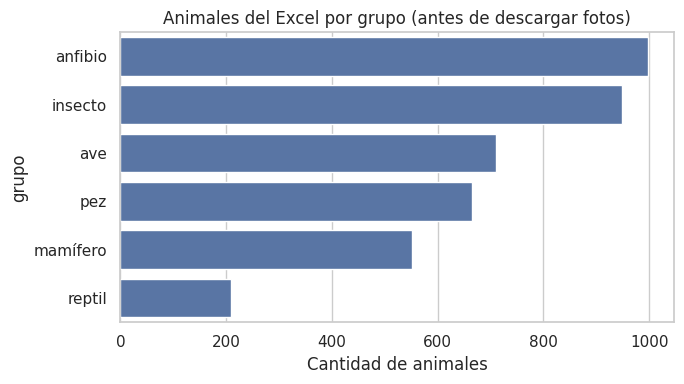

In [5]:
plt.figure(figsize=(7, 4))
sns.countplot(data=tabla, y="grupo", order=tabla["grupo"].value_counts().index, color="#4C72B0")
plt.title("Animales del Excel por grupo (antes de descargar fotos)")
plt.xlabel("Cantidad de animales")
plt.tight_layout()
plt.savefig("imagenes/animales_por_grupo.png", dpi=120)
plt.show()

### Descarga de las fotos

`descargar_imagenes()` (en `src/descargar.py`) le pide a Wikipedia la foto principal de cada animal y guarda hasta
**500 por grupo** en `data/imagenes/<grupo>/`. Solo se aceptan fotos JPG (los PNG/SVG suelen ser mapas o dibujos)
y se evitan fotos repetidas. Además crea `data/manifiesto.csv` con el animal, grupo, archivo y URL de cada foto.

⏱️ Tarda unos 5–15 minutos. Si el archivo `manifiesto.csv` ya existe, este paso se salta.

In [6]:
if RUTA_MANIFIESTO.exists():
    print("Ya hay fotos descargadas: no se descargan de nuevo.")
else:
    descargar_imagenes(tabla, por_grupo=500)

manifiesto = cargar_manifiesto()
print("\nTotal de fotos:", len(manifiesto))
manifiesto["grupo"].value_counts()

anfibio    373 fotos (de 997 animales)
ave        500 fotos (de 710 animales)
insecto    142 fotos (de 948 animales)
mamífero   274 fotos (de 551 animales)
pez        157 fotos (de 664 animales)
reptil     117 fotos (de 209 animales)

Animales descartados y motivos: {'el animal no tiene foto en Wikipedia': 2069, 'la foto no es JPG': 163, 'foto repetida': 202, 'error 429 (demasiadas peticiones)': 6}

Total de fotos: 1563


,count
grupo,
ave,500
anfibio,373
mamífero,274
pez,157
insecto,142
reptil,117


In [7]:
import requests

H = {"User-Agent": "ClasificadorFauna/1.0 (proyecto academico; https://github.com/SebastianCely) python-requests"}
r = requests.get("https://es.wikipedia.org/w/api.php", headers=H, timeout=30, params={
    "action": "query", "format": "json", "prop": "pageimages", "piprop": "thumbnail",
    "pithumbsize": 330, "pilimit": 50, "redirects": 1,
    "titles": "Amazona leucocephala|Panthera onca|Abeja",
})
print("Código de la API:", r.status_code)
print(r.text[:1500])

paginas = r.json().get("query", {}).get("pages", {})
urls = [p["thumbnail"]["source"] for p in paginas.values() if "thumbnail" in p]
print("\nFotos encontradas:", len(urls))
if urls:
    f = requests.get(urls[0], headers=H, timeout=30)
    print("Descarga de prueba:", f.status_code, f.headers.get("content-type"), len(f.content), "bytes")

Código de la API: 200
{"batchcomplete":"","query":{"redirects":[{"from":"Abeja","to":"Anthophila"}],"pages":{"786478":{"pageid":786478,"ns":0,"title":"Amazona leucocephala","thumbnail":{"source":"https://thumb.wikimedia.org/wikipedia/commons/thumb/0/0c/Stavenn_Amazona_leucocephala_00.jpg/330px-Stavenn_Amazona_leucocephala_00.jpg?utm_source=es.wikipedia.org&utm_campaign=api&utm_content=thumbnail","width":330,"height":440}},"26796":{"pageid":26796,"ns":0,"title":"Panthera onca","thumbnail":{"source":"https://thumb.wikimedia.org/wikipedia/commons/thumb/e/e9/Jaguar_%28Panthera_onca_palustris%29_female_Piquiri_River_2.JPG/330px-Jaguar_%28Panthera_onca_palustris%29_female_Piquiri_River_2.JPG?utm_source=es.wikipedia.org&utm_campaign=api&utm_content=thumbnail","width":330,"height":220}},"2108099":{"pageid":2108099,"ns":0,"title":"Anthophila","thumbnail":{"source":"https://thumb.wikimedia.org/wikipedia/commons/thumb/4/44/Honey_bee_on_flower_with_pollen_collected_on_rear_leg.jpg/330px-Honey_bee_

## 2. Exploración y visualización de las imágenes

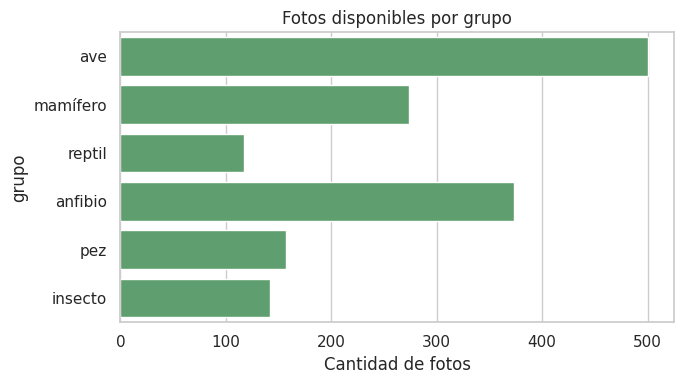

In [8]:
plt.figure(figsize=(7, 4))
sns.countplot(data=manifiesto, y="grupo", order=GRUPOS, color="#55A868")
plt.title("Fotos disponibles por grupo")
plt.xlabel("Cantidad de fotos")
plt.tight_layout()
plt.savefig("imagenes/fotos_por_grupo.png", dpi=120)
plt.show()

Las clases quedan **desbalanceadas** (por ejemplo, hay menos reptiles que anfibios). Lo compensaremos con
*pesos por clase*, *Data Augmentation* y métricas como el **F1 macro**.

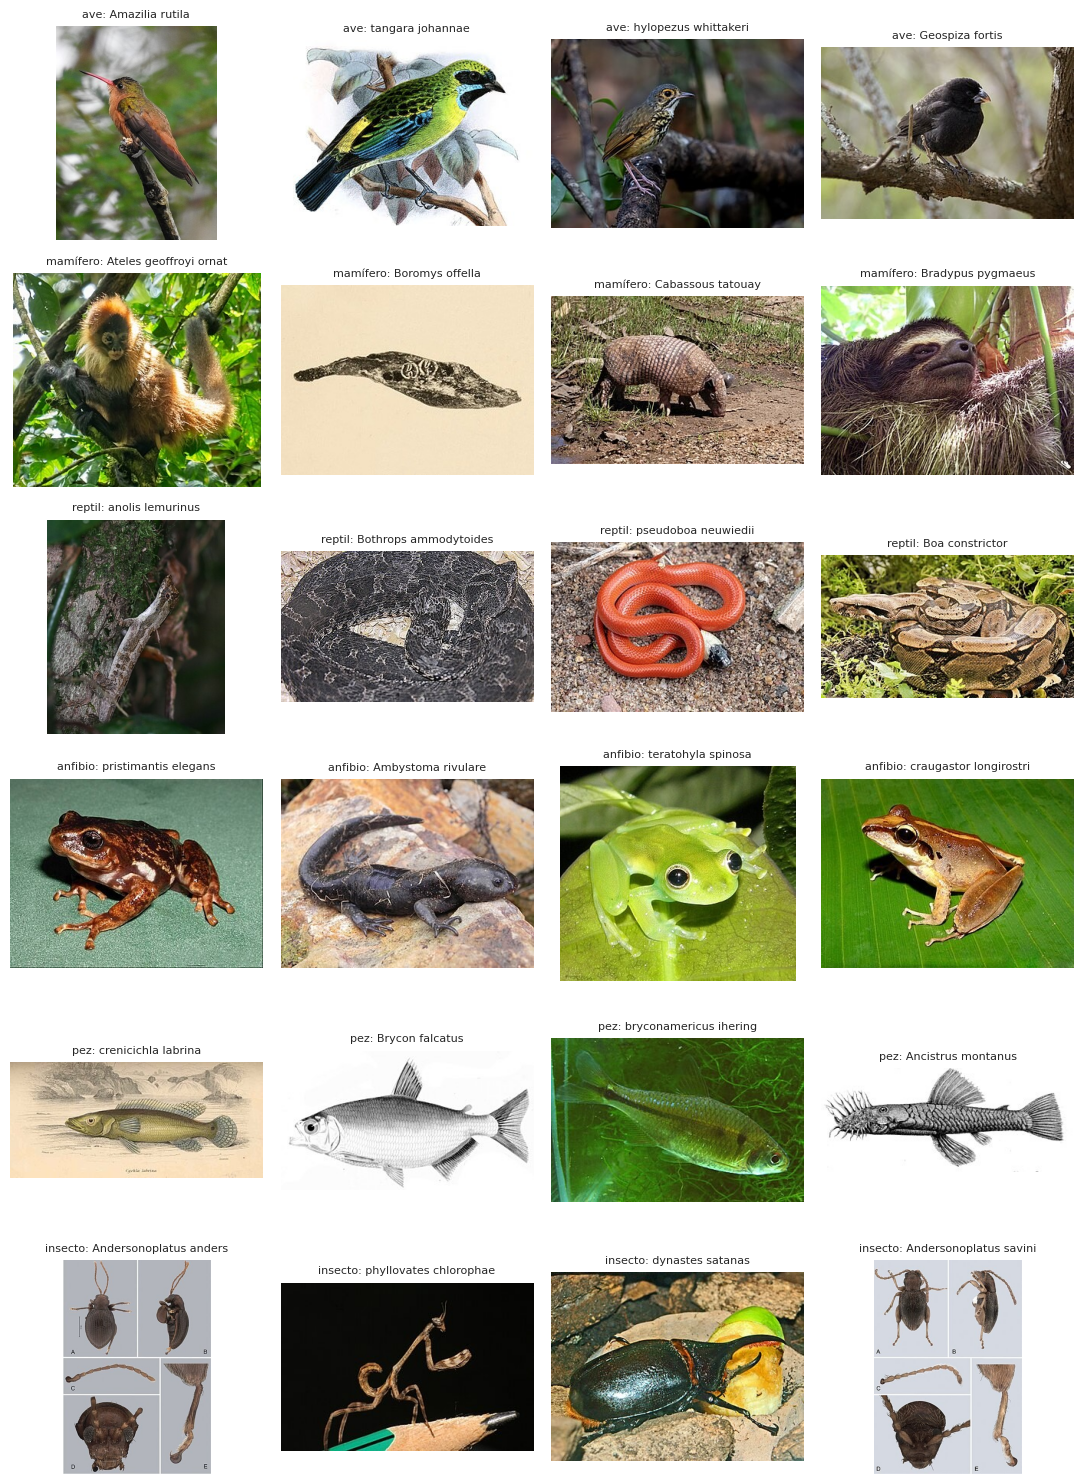

In [9]:
# 4 fotos al azar de cada grupo
fig, ejes = plt.subplots(len(GRUPOS), 4, figsize=(11, 15))
for fila, grupo in enumerate(GRUPOS):
    fotos = manifiesto[manifiesto["grupo"] == grupo].sample(4, random_state=1)
    for col, (_, foto) in enumerate(fotos.iterrows()):
        ejes[fila, col].imshow(Image.open(foto["ruta"]))
        ejes[fila, col].axis("off")
        ejes[fila, col].set_title(f"{grupo}: {foto['entidad'][:22]}", fontsize=8)
plt.tight_layout()
plt.savefig("imagenes/ejemplos_por_grupo.png", dpi=110)
plt.show()

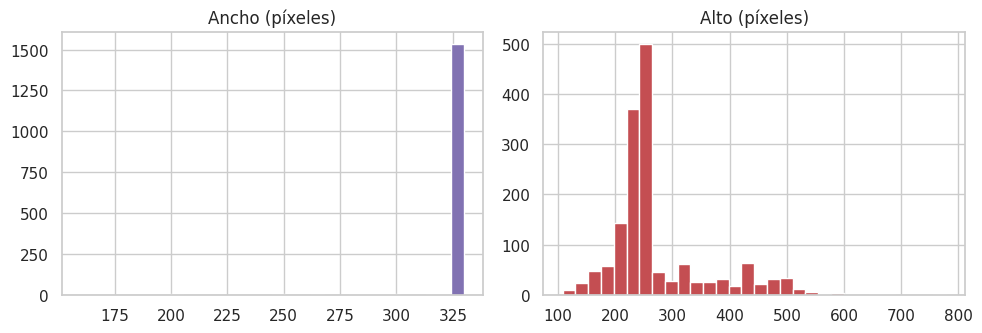

Ancho promedio: 329 | Alto promedio: 271


In [10]:
# Tamaño original de las fotos
tamanos = [Image.open(ruta).size for ruta in manifiesto["ruta"]]
ancho = [t[0] for t in tamanos]
alto = [t[1] for t in tamanos]

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
ejes[0].hist(ancho, bins=30, color="#8172B2"); ejes[0].set_title("Ancho (píxeles)")
ejes[1].hist(alto, bins=30, color="#C44E52"); ejes[1].set_title("Alto (píxeles)")
plt.tight_layout()
plt.savefig("imagenes/tamano_fotos.png", dpi=110)
plt.show()
print(f"Ancho promedio: {np.mean(ancho):.0f} | Alto promedio: {np.mean(alto):.0f}")

Las fotos tienen **tamaños distintos**, pero la red necesita que todas midan lo mismo. Eso lo resolvemos en el preprocesamiento.

## 3. Preprocesamiento y normalización

1. **Redimensionar** todas las fotos a **160 × 160** píxeles (lo hace `crear_dataset()`).
2. **Normalizar** los píxeles (de 0–255 a 0–1, o a −1…1 en MobileNetV2). Esta normalización va **dentro del modelo**
   con una capa `Rescaling`, así la app solo tiene que enviarle la foto tal cual.

In [11]:
original = tf.io.decode_jpeg(tf.io.read_file(manifiesto["ruta"].iloc[0]), channels=3)
redimensionada = tf.image.resize(original, (TAM_IMAGEN, TAM_IMAGEN))

print("Foto original      :", original.shape, "valores de", int(tf.reduce_min(original)), "a", int(tf.reduce_max(original)))
print("Foto redimensionada:", redimensionada.shape)
print("Después de Rescaling(1/255) los valores van de 0 a 1")

Foto original      : (220, 330, 3) valores de 0 a 255
Foto redimensionada: (160, 160, 3)
Después de Rescaling(1/255) los valores van de 0 a 1


## 4. División en entrenamiento, validación y prueba (70 / 15 / 15)

La división conserva la **misma proporción de cada grupo** en los tres conjuntos.
- **Entrenamiento:** la red aprende con estas fotos.
- **Validación:** sirve para ajustar y decidir cuándo parar.
- **Prueba:** fotos que la red nunca vio; se usan solo al final.

In [12]:
train, val, test = dividir_datos(manifiesto)
print(f"Entrenamiento: {len(train)} | Validación: {len(val)} | Prueba: {len(test)}")

pd.DataFrame({
    "Entrenamiento": train["grupo"].value_counts(),
    "Validación": val["grupo"].value_counts(),
    "Prueba": test["grupo"].value_counts(),
}).loc[GRUPOS]

Entrenamiento: 1094 | Validación: 234 | Prueba: 235


,Entrenamiento,Validación,Prueba
grupo,,,
ave,350,75,75
mamífero,192,41,41
reptil,82,18,17
anfibio,261,56,56
pez,110,23,24
insecto,99,21,22


In [13]:
# Cada grupo pasa a ser un número (0, 1, 2, ...)
numero = {grupo: i for i, grupo in enumerate(GRUPOS)}
y_train = train["grupo"].map(numero).to_numpy()
y_val = val["grupo"].map(numero).to_numpy()
y_test = test["grupo"].map(numero).to_numpy()

# Datasets de TensorFlow: leen las fotos, las redimensionan y las entregan en lotes de 32
ds_train = crear_dataset(train["ruta"], y_train, entrenamiento=True)
ds_val = crear_dataset(val["ruta"], y_val)
ds_test = crear_dataset(test["ruta"], y_test)

# Pesos: los grupos con pocas fotos (ej. reptiles) pesan más durante el entrenamiento
pesos = compute_class_weight("balanced", classes=np.arange(len(GRUPOS)), y=y_train)
pesos = dict(enumerate(pesos))
{GRUPOS[i]: round(p, 2) for i, p in pesos.items()}

{'ave': np.float64(0.52),
 'mamífero': np.float64(0.95),
 'reptil': np.float64(2.22),
 'anfibio': np.float64(0.7),
 'pez': np.float64(1.66),
 'insecto': np.float64(1.84)}

## 5. Data Augmentation

Con pocas fotos, la red tiende a **memorizar** en vez de aprender. El *Data Augmentation* crea variaciones de cada foto
(volteada, girada, con zoom o distinto contraste) mientras entrena, como si tuviéramos muchas más fotos.
Es especialmente útil aquí porque hay pocas fotos de algunos grupos. Solo se aplica en entrenamiento, no al predecir.

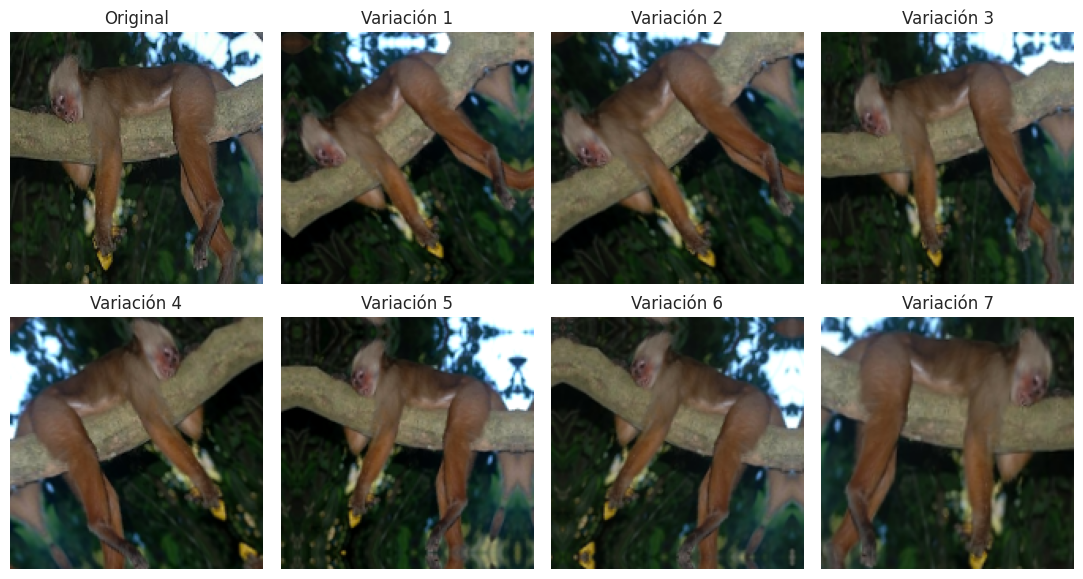

In [14]:
aumento = capa_aumento()
foto = tf.image.resize(
    tf.io.decode_jpeg(tf.io.read_file(train["ruta"].iloc[0]), channels=3), (TAM_IMAGEN, TAM_IMAGEN))

fig, ejes = plt.subplots(2, 4, figsize=(11, 6))
ejes[0, 0].imshow(foto.numpy().astype("uint8"))
ejes[0, 0].set_title("Original")
for i, eje in enumerate(ejes.flatten()[1:]):
    variacion = aumento(tf.expand_dims(foto, 0), training=True)[0]
    eje.imshow(np.clip(variacion.numpy(), 0, 255).astype("uint8"))
    eje.set_title(f"Variación {i + 1}")
for eje in ejes.flatten():
    eje.axis("off")
plt.tight_layout()
plt.savefig("imagenes/data_augmentation.png", dpi=110)
plt.show()

## 6. Construcción y entrenamiento de las CNN

Entrenamos **dos** redes y comparamos:

**A) CNN desde cero** (`crear_cnn`): 4 bloques `Conv2D + MaxPooling` que detectan bordes, texturas y formas,
seguidos de capas densas que deciden la clase.

**B) MobileNetV2 con transferencia de aprendizaje** (`crear_mobilenet`): una CNN ya entrenada con millones de fotos
(ImageNet). Se congela y solo se entrena la capa final. Suele funcionar mejor cuando hay pocas fotos.

El entrenamiento usa *early stopping*: se detiene solo cuando la pérdida de validación deja de mejorar
y se queda con los mejores pesos.

In [15]:
def entrenar(modelo, epocas):
    parar_temprano = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )
    return modelo.fit(
        ds_train,
        validation_data=ds_val,
        epochs=epocas,
        class_weight=pesos,
        callbacks=[parar_temprano],
        verbose=2,
    )

In [16]:
# A) CNN desde cero
modelo_cnn = crear_cnn(len(GRUPOS))
modelo_cnn.summary()
hist_cnn = entrenar(modelo_cnn, epocas=40)

Model: "cnn_desde_cero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 258,118 (1008.27 KB)

 Trainable params: 258,118 (1008.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
35/35 - 7s - 207ms/step - accuracy: 0.1527 - loss: 1.7979 - val_accuracy: 0.2393 - val_loss: 1.7882
Epoch 2/40
35/35 - 1s - 37ms/step - accuracy: 0.1755 - loss: 1.7905 - val_accuracy: 0.0983 - val_loss: 1.8003
Epoch 3/40
35/35 - 3s - 76ms/step - accuracy: 0.1828 - loss: 1.7842 - val_accuracy: 0.0897 - val_loss: 1.8567
Epoch 4/40
35/35 - 2s - 69ms/step - accuracy: 0.1856 - loss: 1.7615 - val_accuracy: 0.1368 - val_loss: 1.7920
Epoch 5/40
35/35 - 3s - 73ms/step - accuracy: 0.2112 - loss: 1.7596 - val_accuracy: 0.2009 - val_loss: 1.7480
Epoch 6/40
35/35 - 3s - 75ms/step - accuracy: 0.2441 - loss: 1.7377 - val_accuracy: 0.2479 - val_loss: 1.7114
Epoch 7/40
35/35 - 1s - 40ms/step - accuracy: 0.2450 - loss: 1.7447 - val_accuracy: 0.2436 - val_loss: 1.7303
Epoch 8/40
35/35 - 1s - 41ms/step - accuracy: 0.2761 - loss: 1.7268 - val_accuracy: 0.2692 - val_loss: 1.7417
Epoch 9/40
35/35 - 2s - 71ms/step - accuracy: 0.2678 - loss: 1.7303 - val_accuracy: 0.2436 - val_loss: 1.7583
Epoch 10/

In [17]:
# B) MobileNetV2 (transferencia de aprendizaje)
modelo_mobilenet = crear_mobilenet(len(GRUPOS))
hist_mobilenet = entrenar(modelo_mobilenet, epocas=20)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/20
35/35 - 8s - 226ms/step - accuracy: 0.4598 - loss: 1.5369 - val_accuracy: 0.7778 - val_loss: 0.6824
Epoch 2/20
35/35 - 2s - 47ms/step - accuracy: 0.7514 - loss: 0.7915 - val_accuracy: 0.8547 - val_loss: 0.4746
Epoch 3/20
35/35 - 2s - 46ms/step - accuracy: 0.8117 - loss: 0.5985 - val_accuracy: 0.8419 - val_loss: 0.4258
Epoch 4/20
35/35 - 2s - 45ms/step - accuracy: 0.8483 - loss: 0.4982 - val_accuracy: 0.8590 - val_loss: 0.3949
Epoch 5/20
35/35 - 2s - 71ms/step - accuracy: 0.8501 - loss: 0.4730 - val_accuracy: 0.8462 - val_loss: 0.4112
Epoch 6/20
35/35 - 1s - 43ms/step - accuracy: 0.8656 - loss: 0.4070 - val_accuracy: 0.8590 - val_loss: 0.4072
Epoch 7/20
35/35 - 2s - 46ms/step - accuracy: 0.8803 - loss: 0.3660 - val_accuracy: 0.8761 - val_loss: 0.3622
Epoch 8/20
35/35 - 2s - 46ms/step - accuracy: 0.8867 - loss: 0.3377 - val_accuracy: 0.8718 - val_loss: 0.3560
Epoch 9/20
35/35 - 2s - 43ms/step - accuracy: 0.8931 - loss: 0.3358 - 

## 7. Gráficas del entrenamiento

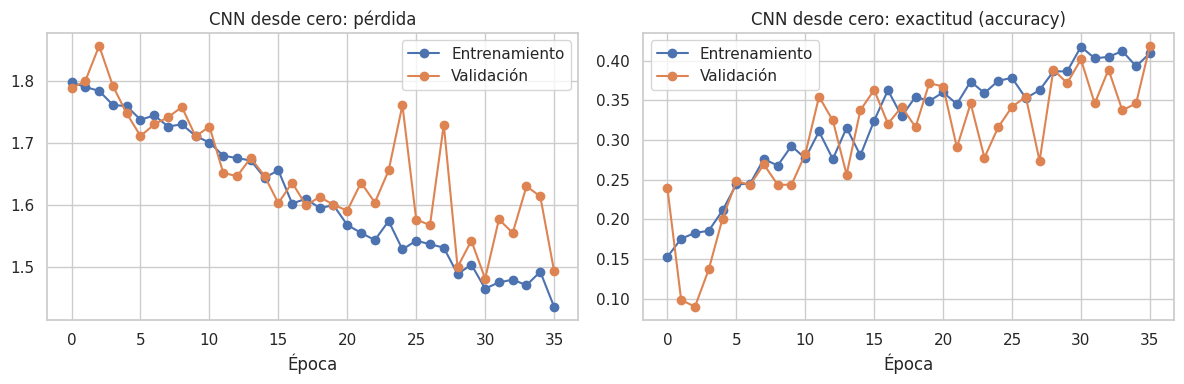

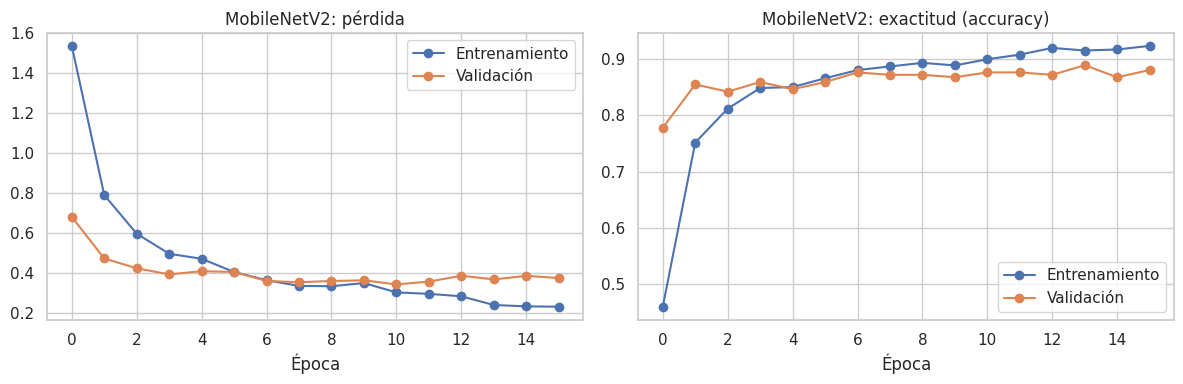

In [18]:
def graficar_historial(historial, titulo, archivo):
    h = historial.history
    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

    ejes[0].plot(h["loss"], label="Entrenamiento", marker="o")
    ejes[0].plot(h["val_loss"], label="Validación", marker="o")
    ejes[0].set_title(f"{titulo}: pérdida")
    ejes[0].set_xlabel("Época")
    ejes[0].legend()

    ejes[1].plot(h["accuracy"], label="Entrenamiento", marker="o")
    ejes[1].plot(h["val_accuracy"], label="Validación", marker="o")
    ejes[1].set_title(f"{titulo}: exactitud (accuracy)")
    ejes[1].set_xlabel("Época")
    ejes[1].legend()

    plt.tight_layout()
    plt.savefig(archivo, dpi=120)
    plt.show()


graficar_historial(hist_cnn, "CNN desde cero", "imagenes/entrenamiento_cnn.png")
graficar_historial(hist_mobilenet, "MobileNetV2", "imagenes/entrenamiento_mobilenet.png")

## 8. Evaluación con métricas apropiadas

- **Accuracy:** porcentaje de fotos bien clasificadas.
- **F1 macro:** promedio del F1 de cada grupo; no deja que los grupos grandes tapen a los pequeños (reptiles).
- **Matriz de confusión:** muestra qué grupos se confunden entre sí.

Elegimos el mejor modelo por su F1 en **validación**, y reportamos su resultado en **prueba**.

In [19]:
def evaluar(modelo, ds, y_real):
    pred = modelo.predict(ds, verbose=0).argmax(axis=1)
    return pred, accuracy_score(y_real, pred), f1_score(y_real, pred, average="macro")


modelos = {"CNN desde cero": modelo_cnn, "MobileNetV2": modelo_mobilenet}
filas, predicciones_test = [], {}
for nombre, modelo in modelos.items():
    _, acc_val, f1_val = evaluar(modelo, ds_val, y_val)
    pred_test, acc_test, f1_test = evaluar(modelo, ds_test, y_test)
    predicciones_test[nombre] = pred_test
    filas.append({"Modelo": nombre, "Accuracy val": acc_val, "F1 val": f1_val,
                  "Accuracy prueba": acc_test, "F1 prueba": f1_test})

comparacion = pd.DataFrame(filas).round(3)
mejor_nombre = comparacion.loc[comparacion["F1 val"].idxmax(), "Modelo"]
mejor_modelo = modelos[mejor_nombre]
pred_mejor = predicciones_test[mejor_nombre]
print("Mejor modelo (según validación):", mejor_nombre)
comparacion

Mejor modelo (según validación): MobileNetV2


,Modelo,Accuracy val,F1 val,Accuracy prueba,F1 prueba
0,CNN desde cero,0.402,0.361,0.404,0.372
1,MobileNetV2,0.876,0.844,0.877,0.840


In [20]:
print(classification_report(y_test, pred_mejor, target_names=GRUPOS, zero_division=0))

              precision    recall  f1-score   support

         ave       0.97      0.97      0.97        75
    mamífero       0.87      0.95      0.91        41
      reptil       0.60      0.71      0.65        17
     anfibio       0.88      0.77      0.82        56
         pez       0.84      0.88      0.86        24
     insecto       0.86      0.82      0.84        22

    accuracy                           0.88       235
   macro avg       0.84      0.85      0.84       235
weighted avg       0.88      0.88      0.88       235



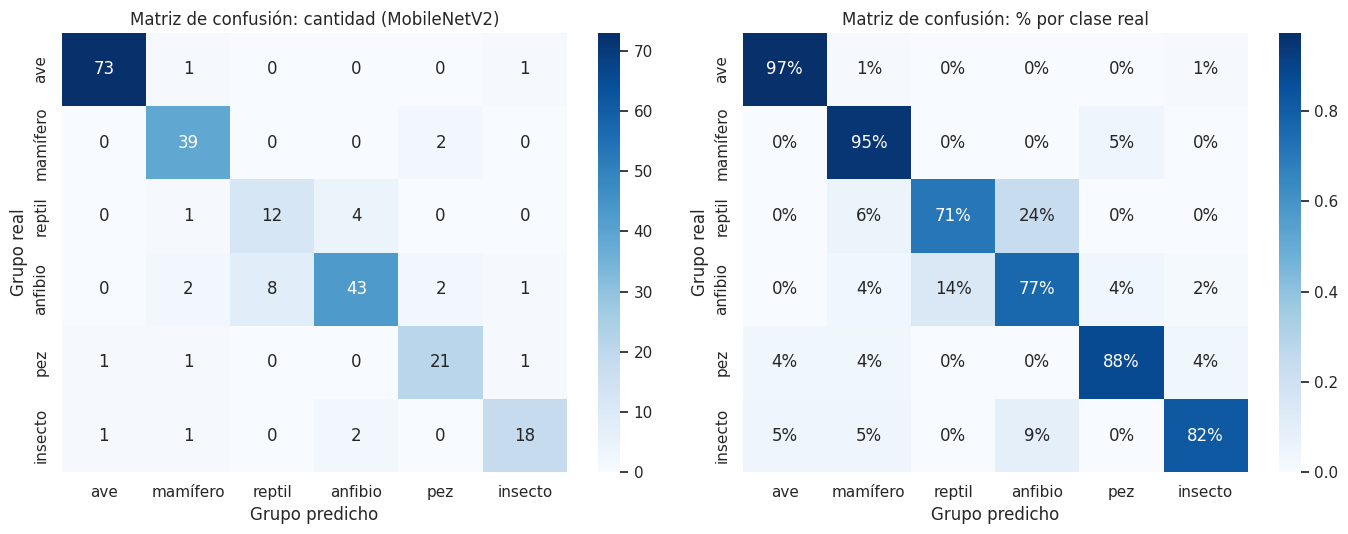

In [21]:
matriz = confusion_matrix(y_test, pred_mejor)
matriz_pct = confusion_matrix(y_test, pred_mejor, normalize="true")

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=GRUPOS, yticklabels=GRUPOS, ax=ejes[0])
ejes[0].set_title(f"Matriz de confusión: cantidad ({mejor_nombre})")
sns.heatmap(matriz_pct, annot=True, fmt=".0%", cmap="Blues", xticklabels=GRUPOS, yticklabels=GRUPOS, ax=ejes[1])
ejes[1].set_title("Matriz de confusión: % por clase real")
for eje in ejes:
    eje.set_xlabel("Grupo predicho")
    eje.set_ylabel("Grupo real")
plt.tight_layout()
plt.savefig("imagenes/matriz_confusion.png", dpi=120)
plt.show()

In [22]:
# ¿Qué grupos se confunden más?
errores = matriz.copy()
np.fill_diagonal(errores, 0)
mas_confundidos = np.dstack(np.unravel_index(np.argsort(errores, axis=None)[::-1][:3], errores.shape))[0]
print("Confusiones más frecuentes (real -> predicho):")
for real, predicho in mas_confundidos:
    if errores[real, predicho] > 0:
        print(f"  {GRUPOS[real]} -> {GRUPOS[predicho]}: {errores[real, predicho]} fotos")

Confusiones más frecuentes (real -> predicho):
  anfibio -> reptil: 8 fotos
  reptil -> anfibio: 4 fotos
  insecto -> anfibio: 2 fotos


## 9. Predicciones con imágenes (15 fotos de prueba)

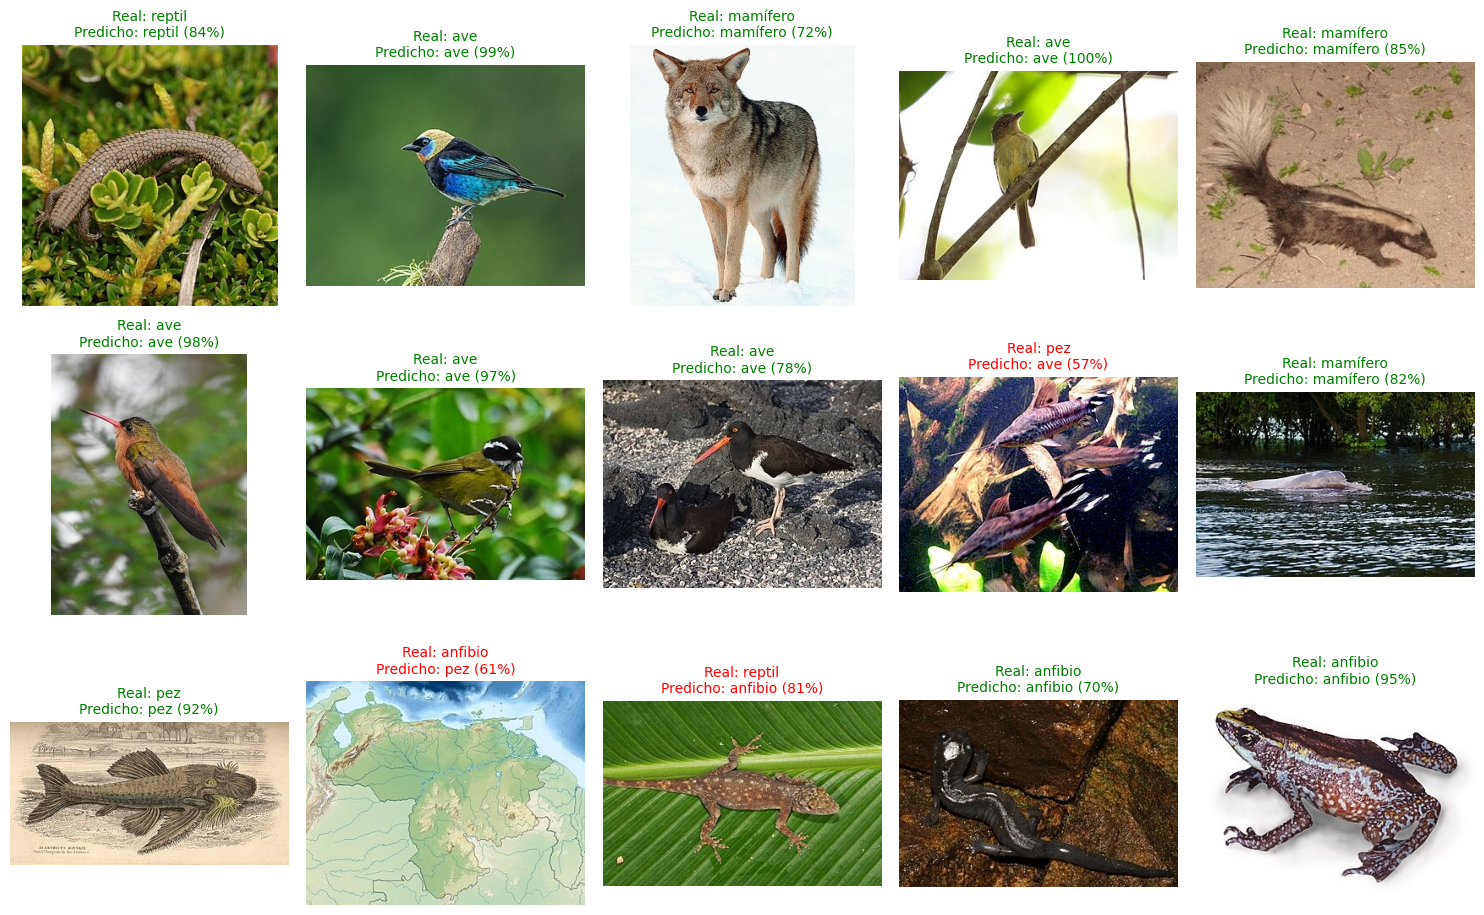

In [23]:
muestra = test.sample(15, random_state=7)
y_muestra = muestra["grupo"].map(numero).to_numpy()
probs = mejor_modelo.predict(crear_dataset(muestra["ruta"], y_muestra), verbose=0)

fig, ejes = plt.subplots(3, 5, figsize=(15, 9.5))
for eje, (_, foto), p in zip(ejes.flatten(), muestra.iterrows(), probs):
    predicho = GRUPOS[p.argmax()]
    acerto = predicho == foto["grupo"]
    eje.imshow(Image.open(foto["ruta"]))
    eje.axis("off")
    eje.set_title(f"Real: {foto['grupo']}\nPredicho: {predicho} ({p.max():.0%})",
                  fontsize=10, color="green" if acerto else "red")
plt.tight_layout()
plt.savefig("imagenes/predicciones_prueba.png", dpi=110)
plt.show()

## 10. Guardado del modelo entrenado

In [24]:
os.makedirs("modelo", exist_ok=True)
mejor_modelo.save("modelo/modelo.keras")      # incluye normalización y augmentation
with open("modelo/clases.json", "w", encoding="utf-8") as f:
    json.dump(GRUPOS, f, ensure_ascii=False)

fila = comparacion[comparacion["Modelo"] == mejor_nombre].iloc[0]
with open("modelo/metricas.json", "w", encoding="utf-8") as f:
    json.dump({"modelo": mejor_nombre, "accuracy": float(fila["Accuracy prueba"]),
               "f1_macro": float(fila["F1 prueba"])}, f, indent=2)

# Comprobamos que el modelo guardado funciona igual que el original
from predecir import cargar_modelo, predecir
modelo_cargado, clases = cargar_modelo()
foto = test.iloc[0]
print("Foto de prueba:", foto["entidad"], "| grupo real:", foto["grupo"])
for clase, prob in predecir(modelo_cargado, clases, Image.open(foto["ruta"]))[:3]:
    print(f"   {clase:<10} {prob:.1%}")

Foto de prueba: Crenicichla hu | grupo real: pez
   pez        97.6%
   mamífero   1.3%
   ave        0.4%


### Guardar los resultados de Colab

Colab borra sus archivos al cerrar la sesión. Ejecuta la celda siguiente para **descargar** el modelo, las gráficas y las
fotos, y súbelos a tu repositorio de GitHub. Para que este notebook quede **con sus resultados** en el repositorio:
*Archivo → Guardar una copia en GitHub*.

In [25]:
if EN_COLAB:
    from google.colab import files
    for carpeta in ["modelo", "imagenes", os.path.join("data", "imagenes")]:
        shutil.make_archive(carpeta.replace(os.sep, "_"), "zip", carpeta)
        files.download(carpeta.replace(os.sep, "_") + ".zip")
    files.download(os.path.join("data", "manifiesto.csv"))
else:
    print("Fuera de Colab no hace falta descargar nada: los archivos ya están en tu carpeta.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusiones

- Se construyó un clasificador de **6 grupos de fauna** a partir de fotos, usando el Excel para **etiquetar** y para
  **encontrar las fotos** de cada animal.
- Se compararon una **CNN desde cero** y **MobileNetV2** (transferencia de aprendizaje); la comparación y el mejor
  modelo están en la sección 8.
- El **Data Augmentation** y los **pesos por clase** ayudan a compensar que hay pocas fotos y que los grupos están
  desbalanceados.
- **Limitaciones:** las etiquetas salen de palabras clave (pueden tener algún error), las fotos de Wikipedia son variadas
  (animal pequeño en el fondo, ejemplares disecados, etc.) y no todos los animales tienen foto.
- **Mejoras posibles:** *fine-tuning* de las últimas capas de MobileNetV2, más fotos por grupo, limpiar a mano
  fotos dudosas, o agregar más clases (arácnidos, moluscos).